In [16]:
%mamba install pandas


mambajs 0.21.4

Specs: xeus-python, numpy, matplotlib, pillow, ipywidgets>=8.1.6, ipyleaflet, scipy, pandas
Channels: emscripten-forge-4x, conda-forge

Solving environment...
Solving took 8.263 seconds
  Name           Version  Build                Channel
--------------------------------------------------------------------
+ pandas         3.1.0    np23py313h124dbc7_0  emscripten-forge-4x
+ python-tzdata  2026.5   pyh5ded981_0         conda-forge
- pip            26.2.1   pyh145f28c_0         conda-forge


In [17]:
# Part B - Gradient Descent

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Reuse B_df if already loaded; otherwise read the CSV
if "B_df" not in globals():
    B_df = pd.read_csv(Path.cwd() / "B_pv_plant.csv")

# Check required columns
required_columns = {
    "irradiance_Wm2",
    "module_temp_C",
    "ac_power_kW"
}

missing = required_columns - set(B_df.columns)

if missing:
    raise ValueError(f"Missing columns: {missing}")

# Input features and target
G = B_df["irradiance_Wm2"].to_numpy(dtype=float)
Tm = B_df["module_temp_C"].to_numpy(dtype=float)
y = B_df["ac_power_kW"].to_numpy(dtype=float)

m = len(y)

# Raw design matrix: intercept, irradiance, module temperature
X_raw = np.column_stack([
    np.ones(m),
    G,
    Tm
])

print("Dataset shape:", B_df.shape)
print("Design matrix shape:", X_raw.shape)
display(B_df.head())

Dataset shape: (500, 3)
Design matrix shape: (500, 3)


,irradiance_Wm2,module_temp_C,ac_power_kW
0,396.3,28.4,1.894
1,493.7,35.7,2.164
2,865.8,49.5,3.968
3,737.5,41.3,3.354
4,350.4,32.5,1.564


In [18]:
# B1 - Closed form least squares solution

theta_star_raw = np.linalg.lstsq(
    X_raw, y, rcond=None
)[0]

yhat_star_raw = X_raw @ theta_star_raw

J_star = np.mean((yhat_star_raw - y) ** 2)

print("B1: Reference solution")
print(f"theta0*: {theta_star_raw[0]:.4f} kW")
print(f"theta1*: {theta_star_raw[1]:.6f}")
print(f"theta2*: {theta_star_raw[2]:.6f}")
print(f"J*:      {J_star:.6f} kW^2")

B1: Reference solution
theta0*: 0.2116 kW
theta1*: 0.004929
theta2*: -0.011111
J*:      0.009974 kW^2


In [19]:
# Common functions for B2 and B4

def mse_cost(X, y, theta):
    """Calculate mean squared error."""
    predictions = X @ theta
    return np.mean((predictions - y) ** 2)


def batch_gradient_descent(
    X, y, eta, J_reference,
    max_iter=200_000,
    tolerance=1e-6
):
    """
    Batch gradient descent starting from zero.

    Returns:
        theta, status, iterations, final_cost, relative_gap
    """

    m_local = len(y)
    theta = np.zeros(X.shape[1], dtype=float)

    initial_cost = mse_cost(X, y, theta)
    current_cost = initial_cost
    status = "max_iterations"
    iterations = 0

    for iteration in range(1, max_iter + 1):

        # Full-data gradient
        gradient = (
            2 / m_local
        ) * X.T @ (X @ theta - y)

        # Update coefficients
        theta = theta - eta * gradient

        # Calculate updated cost
        current_cost = mse_cost(X, y, theta)
        iterations = iteration

        # Divergence check
        if current_cost > 1e6 * initial_cost:
            status = "diverged"
            break

        # Relative optimality gap
        relative_gap = (
            (current_cost - J_reference) / J_reference
            if J_reference > 0 else np.nan
        )

        if relative_gap < tolerance:
            status = "converged"
            break

    relative_gap = (
        (current_cost - J_reference) / J_reference
        if J_reference > 0 else np.nan
    )

    return {
        "theta": theta,
        "status": status,
        "iterations": iterations,
        "final_cost": current_cost,
        "relative_gap": relative_gap
    }

In [20]:
# B2 - Standardise input features

G_mean = G.mean()
G_std = G.std(ddof=0)

Tm_mean = Tm.mean()
Tm_std = Tm.std(ddof=0)

if G_std == 0 or Tm_std == 0:
    raise ValueError("A feature has zero standard deviation.")

G_z = (G - G_mean) / G_std
Tm_z = (Tm - Tm_mean) / Tm_std

X_std = np.column_stack([
    np.ones(m),
    G_z,
    Tm_z
])

print("Standardised design matrix shape:", X_std.shape)

Standardised design matrix shape: (500, 3)


In [21]:
# B2 - Hessian summary

def hessian_summary(X):
    m_local = X.shape[0]

    H = (2 / m_local) * (X.T @ X)

    eigenvalues = np.linalg.eigvalsh(H)

    lambda_min = eigenvalues[0]
    lambda_max = eigenvalues[-1]

    condition_number = (
        lambda_max / lambda_min
        if lambda_min > 0 else np.inf
    )

    stability_limit = 2 / lambda_max

    return {
        "H": H,
        "eigenvalues": eigenvalues,
        "lambda_min": lambda_min,
        "lambda_max": lambda_max,
        "condition_number": condition_number,
        "stability_limit": stability_limit
    }


raw_info = hessian_summary(X_raw)
std_info = hessian_summary(X_std)

for name, info in [
    ("Raw features", raw_info),
    ("Standardised features", std_info)
]:
    print(f"\n{name}")
    print("Eigenvalues:", info["eigenvalues"])
    print("Condition number:", info["condition_number"])
    print("Stability limit:", info["stability_limit"])


Raw features
Eigenvalues: [4.11282126e-02 1.83405898e+02 7.79710137e+05]
Condition number: 18958036.0443477
Stability limit: 2.565055789431085e-06

Standardised features
Eigenvalues: [0.11691656 2.         3.88308344]
Condition number: 33.21243265439052
Stability limit: 0.515054603352998


In [22]:
# B2 - Batch gradient descent comparison

eta_raw = 1 / raw_info["lambda_max"]
eta_std = 1 / std_info["lambda_max"]

result_raw = batch_gradient_descent(
    X_raw, y, eta_raw, J_star
)

# The optimal MSE is unchanged by standardising input features
result_std = batch_gradient_descent(
    X_std, y, eta_std, J_star
)

B2_results = pd.DataFrame([
    {
        "features": "Raw",
        "eta": eta_raw,
        "condition_number": raw_info["condition_number"],
        "status": result_raw["status"],
        "iterations": result_raw["iterations"],
        "final_MSE": result_raw["final_cost"],
        "relative_gap": result_raw["relative_gap"]
    },
    {
        "features": "Standardised",
        "eta": eta_std,
        "condition_number": std_info["condition_number"],
        "status": result_std["status"],
        "iterations": result_std["iterations"],
        "final_MSE": result_std["final_cost"],
        "relative_gap": result_std["relative_gap"]
    }
])

display(B2_results)

,features,eta,condition_number,status,iterations,final_MSE,relative_gap
0,Raw,0.000001,1.895804e+07,max_iterations,200000,0.010878,9.066418e-02
1,Standardised,0.257527,3.321243e+01,converged,257,0.009974,9.806384e-07


In [23]:
# B3 - Closed form fit using standardised features

theta_star_std = np.linalg.lstsq(
    X_std, y, rcond=None
)[0]

# Convert standardised coefficients back to raw units
theta1_back = theta_star_std[1] / G_std
theta2_back = theta_star_std[2] / Tm_std

theta0_back = (
    theta_star_std[0]
    - theta_star_std[1] * G_mean / G_std
    - theta_star_std[2] * Tm_mean / Tm_std
)

theta_back_raw = np.array([
    theta0_back,
    theta1_back,
    theta2_back
])

B3_results = pd.DataFrame({
    "coefficient": ["Intercept", "Irradiance", "Temperature"],
    "Raw_B1": theta_star_raw,
    "Converted_from_standardised": theta_back_raw,
    "Absolute_difference": np.abs(
        theta_star_raw - theta_back_raw
    )
})

display(B3_results)

print(
    "Largest absolute coefficient difference:",
    np.max(np.abs(theta_star_raw - theta_back_raw))
)

,coefficient,Raw_B1,Converted_from_standardised,Absolute_difference
0,Intercept,0.211631,0.211631,2.386980e-15
1,Irradiance,0.004929,0.004929,1.734723e-18
2,Temperature,-0.011111,-0.011111,7.806256e-17


Largest absolute coefficient difference: 2.3869795029440866e-15


In [24]:
# B4 - Learning-rate sweep

k_values = [0.1, 0.5, 0.99, 1.01]
results_B4 = []

for k in k_values:

    eta = k * std_info["stability_limit"]

    result = batch_gradient_descent(
        X_std,
        y,
        eta,
        J_star
    )

    results_B4.append({
        "k": k,
        "eta": eta,
        "status": result["status"],
        "iterations": result["iterations"],
        "final_MSE": result["final_cost"],
        "relative_gap": result["relative_gap"]
    })

B4_results = pd.DataFrame(results_B4)

display(B4_results)

,k,eta,status,iterations,final_MSE,relative_gap
0,0.10,0.051505,converged,1300,9.973927e-03,9.902813e-07
1,0.50,0.257527,converged,257,9.973927e-03,9.806384e-07
2,0.99,0.509904,converged,469,9.973926e-03,9.607322e-07
3,1.01,0.520205,diverged,390,8.308891e+06,8.330620e+08


In [25]:
# B5 - Mini batch gradient descent

def minibatch_gradient_descent(
    X,
    y,
    theta_reference,
    epochs=20,
    schedule=None,
    seed=0,
    batch_size=32
):
    rng = np.random.default_rng(seed)

    m_local = len(y)
    theta = np.zeros(X.shape[1], dtype=float)

    distances = [
        np.linalg.norm(theta - theta_reference)
    ]

    t = 0

    for epoch in range(epochs):

        # Shuffle once at the start of every epoch
        idx = rng.permutation(m_local)

        for start in range(0, m_local, batch_size):

            batch_idx = idx[start:start + batch_size]

            X_batch = X[batch_idx]
            y_batch = y[batch_idx]

            eta = schedule(t)

            gradient = (
                2 / len(batch_idx)
            ) * X_batch.T @ (
                X_batch @ theta - y_batch
            )

            theta = theta - eta * gradient

            # Increase counter once per batch
            t += 1

        # Distance after the completed epoch
        distance = np.linalg.norm(
            theta - theta_reference
        )

        distances.append(distance)

    return theta, np.asarray(distances)

In [26]:
# B5 - Running the required and comparison schedules

required_schedule = lambda t: 5 / (t + 50)

# A second schedule for comparison
comparison_schedule = lambda t: 1 / (t + 20)

epochs = 20

theta_mb_required, distances_required = (
    minibatch_gradient_descent(
        X_std,
        y,
        theta_star_std,
        epochs=epochs,
        schedule=required_schedule,
        seed=0,
        batch_size=32
    )
)

theta_mb_comparison, distances_comparison = (
    minibatch_gradient_descent(
        X_std,
        y,
        theta_star_std,
        epochs=epochs,
        schedule=comparison_schedule,
        seed=0,
        batch_size=32
    )
)

# Display distances after epochs 1, 5, and 20
B5_results = pd.DataFrame({
    "epoch": [1, 5, 20],
    "required_schedule_distance": [
        distances_required[1],
        distances_required[5],
        distances_required[20]
    ],
    "comparison_schedule_distance": [
        distances_comparison[1],
        distances_comparison[5],
        distances_comparison[20]
    ]
})

display(B5_results)

,epoch,required_schedule_distance,comparison_schedule_distance
0,1,0.877788,1.219202
1,5,0.584388,0.868532
2,20,0.316266,0.748527


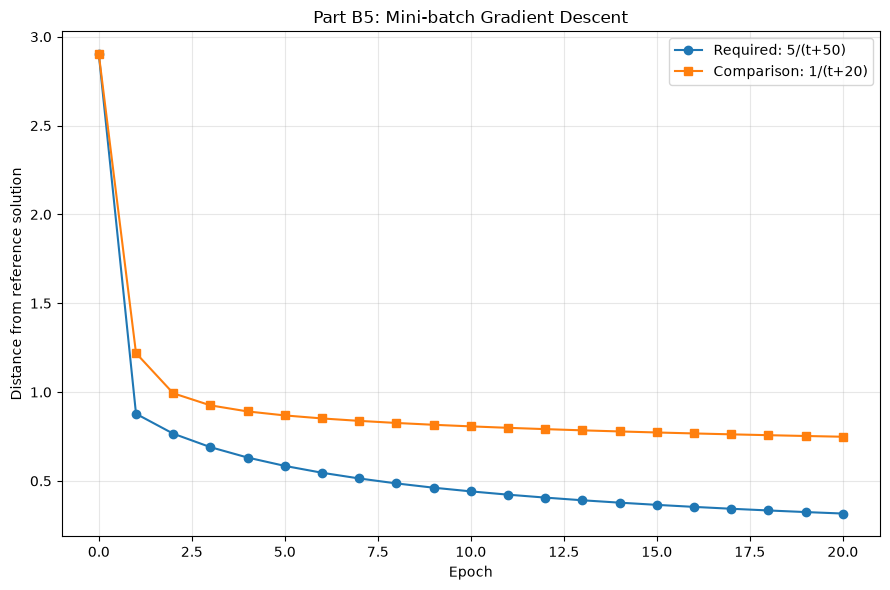

Saved plot as B5_minibatch.png


In [27]:
# B5 - Plot and save the convergence comparison

epoch_numbers = np.arange(epochs + 1)

plt.figure(figsize=(9, 6))

plt.plot(
    epoch_numbers,
    distances_required,
    marker="o",
    label="Required: 5/(t+50)"
)

plt.plot(
    epoch_numbers,
    distances_comparison,
    marker="s",
    label="Comparison: 1/(t+20)"
)

plt.xlabel("Epoch")
plt.ylabel(r"Distance from reference solution")
plt.title("Part B5: Mini-batch Gradient Descent")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()

plt.savefig(
    "B5_minibatch.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("Saved plot as B5_minibatch.png")